# Notebook 01: Preprocesamiento de datos
Se explora el dataset, se define el diccionario de datos y prepara los datos para el modelado.

In [6]:
import pandas as pd  # manejo del DataFrame
import numpy as np  # operaciones numéricas
import matplotlib.pyplot as plt  # graficas
import seaborn as sns  # estadisticas

pd.set_option("display.float_format", "{:,.2f}".format)  # muestra los números con comas y 2 decimales
sns.set_theme(style="whitegrid")  # estilo de fondo claro con cuadrícula para todas las gráficas

RUTA_CSV = "../data/raw/PS_20174392719_1491204439457_log.csv"  #ruta del dataset
df = pd.read_csv(RUTA_CSV, dtype={"type": "category"})  # cargamos el dataset a un df
print("Filas y columnas:", df.shape)  # numero de filas y columnas
df.head()  # primeras 5 filas

Filas y columnas: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


In [7]:
print("\nNulos por columna:")
print(df.isnull().sum())  # valores vacíos, si hay se imputan
print("\nFilas duplicadas:", df.duplicated().sum())  # filas repetidas, se eliminan


Nulos por columna:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Filas duplicadas: 0


         cantidad  porcentaje
isFraud                      
0         6354407       99.87
1            8213        0.13

Hay 774 transacciones normales por cada fraude


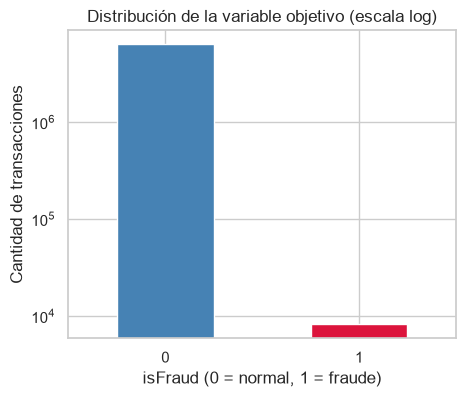

In [8]:
conteo = df["isFraud"].value_counts() 
porcentaje = df["isFraud"].value_counts(normalize=True) * 100
resumen = pd.DataFrame({"cantidad": conteo, "porcentaje": porcentaje})
print(resumen) #tabla de cuantas columnas hay que son fraude o no

ratio = conteo[0] / conteo[1]  # normales por cada fraude
print(f"\nHay {ratio:,.0f} transacciones normales por cada fraude")

ax = conteo.plot(kind="bar", color=["steelblue", "crimson"], logy=True, figsize=(5, 4))  # logy: escala logarítmica
ax.set_title("Distribución de la variable objetivo (escala log)")
ax.set_xlabel("isFraud (0 = normal, 1 = fraude)")
ax.set_ylabel("Cantidad de transacciones")
plt.xticks(rotation=0)  # etiquetas del eje X en horizontal
plt.show() #graficamos

In [9]:
por_tipo = df.groupby("type", observed=True)["isFraud"].agg(
    total="count",  # transacciones totales de ese tipo
    fraudes="sum",  # cuántas son fraude (sumar unos y ceros)
    tasa="mean",  # proporción de fraude
)
por_tipo["tasa"] = por_tipo["tasa"] * 100  # convertimos a porcentaje
print(por_tipo)

            total  fraudes  tasa
type                            
CASH_IN   1399284        0  0.00
CASH_OUT  2237500     4116  0.18
DEBIT       41432        0  0.00
PAYMENT   2151495        0  0.00
TRANSFER   532909     4097  0.77


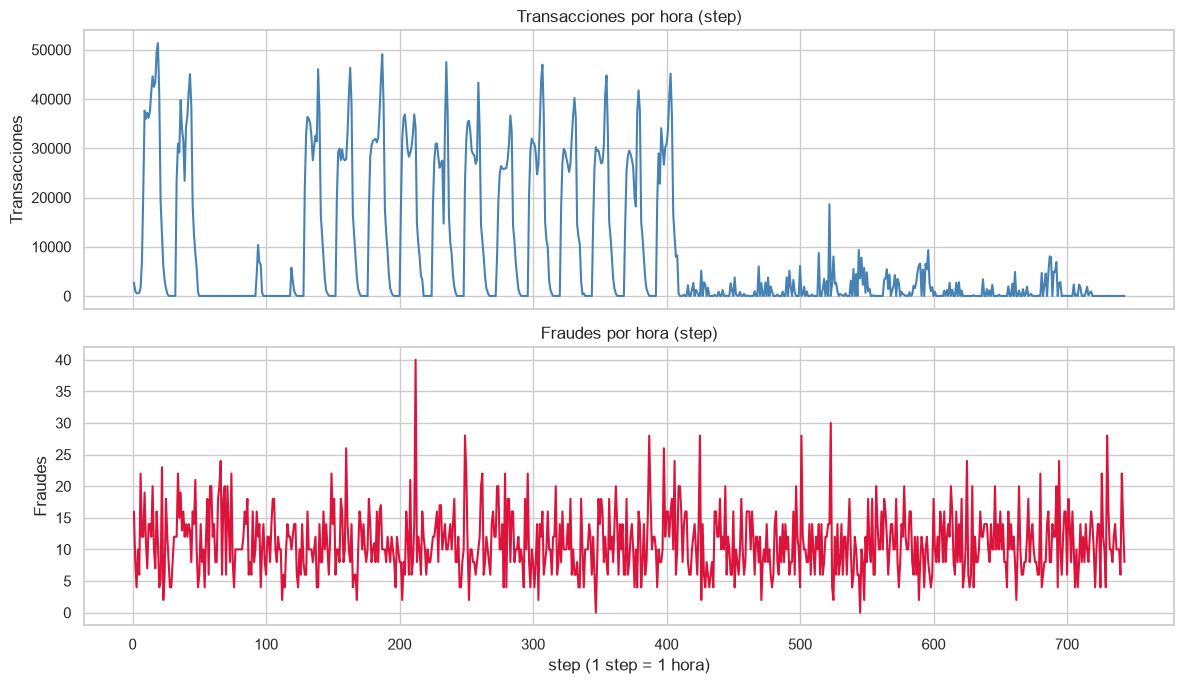

In [10]:
fraudes_por_step = df.groupby("step")["isFraud"].sum()  # fraudes en cada hora simulada
trans_por_step = df.groupby("step").size()  # total de transacciones en cada hora

fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)  # 2 gráficas apiladas con el mismo eje X

ejes[0].plot(trans_por_step.index, trans_por_step.values, color="steelblue")
ejes[0].set_title("Transacciones por hora (step)")
ejes[0].set_ylabel("Transacciones")

ejes[1].plot(fraudes_por_step.index, fraudes_por_step.values, color="crimson")
ejes[1].set_title("Fraudes por hora (step)")
ejes[1].set_ylabel("Fraudes")
ejes[1].set_xlabel("step (1 step = 1 hora)")

plt.tight_layout()  # evita que se solapen los textos
plt.show()

In [11]:
fraudes = df[df["isFraud"] == 1]  # nos quedamos solo con las filas fraudulentas

pct_vacia_origen = (fraudes["newbalanceOrig"] == 0).mean() * 100  # % de fraudes que dejan la cuenta origen en 0
pct_destino_cero = (fraudes["oldbalanceDest"] == 0).mean() * 100  # % de fraudes hacia cuentas destino vacías

print(f"Fraudes que vacían la cuenta origen: {pct_vacia_origen:.1f}%")
print(f"Fraudes hacia cuentas destino con saldo 0: {pct_destino_cero:.1f}%")

print("\nPrefijo de la cuenta destino en fraudes (C = cliente, M = comercio):")
print(fraudes["nameDest"].str[0].value_counts())  # primera letra de cada nameDest

print("\nMonto (amount) en fraudes vs normales:")
print(df.groupby("isFraud")["amount"].describe())  # estadísticas de amount por clase

Fraudes que vacían la cuenta origen: 98.1%
Fraudes hacia cuentas destino con saldo 0: 65.2%

Prefijo de la cuenta destino en fraudes (C = cliente, M = comercio):
nameDest
C    8213
Name: count, dtype: int64

Monto (amount) en fraudes vs normales:
               count         mean          std  min        25%        50%  \
isFraud                                                                     
0       6,354,407.00   178,197.04   596,236.98 0.01  13,368.40  74,684.72   
1           8,213.00 1,467,967.30 2,404,252.95 0.00 127,091.33 441,423.44   

                 75%           max  
isFraud                             
0         208,364.76 92,445,516.64  
1       1,517,771.48 10,000,000.00  


## Resultados
- Sin nulos ni duplicados. Desbalance: 774 normales por fraude (0.129%).
- El fraude ocurre solo en TRANSFER y CASH_OUT, así que el modelo se limita a esos tipos.
- El volumen cae después del paso 400 mientras los fraudes por hora se mantienen: la tasa de fraude sube de 0.15% a 3.7% (cambio de prevalencia).
- La regla del sistema (isFlaggedFraud) detecta solo 16 de 8,213 fraudes.
- Se descarta nameOrig y nameDest. Se crean variables de error de saldo, saldos vacíos y hora del día.

In [12]:
TIPOS_CON_FRAUDE = ["TRANSFER", "CASH_OUT"]  # únicos tipos donde existe fraude
df_m = df[df["type"].isin(TIPOS_CON_FRAUDE)].copy()  # filtramos y copiamos para no modificar df
df_m["type"] = df_m["type"].astype(str)  # categoría a texto simple
print("Filas tras filtrar:", df_m.shape[0])  # esperado: 2,770,409

# Error de saldo: si la operación es consistente, estos valores valen 0
df_m["errorBalanceOrig"] = df_m["newbalanceOrig"] + df_m["amount"] - df_m["oldbalanceOrg"]
df_m["errorBalanceDest"] = df_m["oldbalanceDest"] + df_m["amount"] - df_m["newbalanceDest"]

df_m["origenVacio"] = (df_m["oldbalanceOrg"] == 0).astype("int8")  # 1 si el origen no tenía saldo
df_m["destinoVacio"] = (df_m["oldbalanceDest"] == 0).astype("int8")  # 1 si el destino no tenía saldo
df_m["hora_dia"] = (df_m["step"] % 24).astype("int8")  # hora del día (0 a 23)
df_m["es_transfer"] = (df_m["type"] == "TRANSFER").astype("int8")  # 1 = TRANSFER, 0 = CASH_OUT

FEATURES = [
    "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "errorBalanceOrig", "errorBalanceDest", "origenVacio", "destinoVacio",
    "hora_dia", "es_transfer",
]  # variables que usará el modelo
OBJETIVO = "isFraud"  # variable a predecir
print("Número de variables:", len(FEATURES))

Filas tras filtrar: 2770409
Número de variables: 11


In [13]:
train = df_m[df_m["step"] <= 400]  # el pasado: se entrena aquí
test = df_m[(df_m["step"] > 400) & (df_m["step"] <= 600)]  # el futuro cercano: métricas offline
prod = df_m[df_m["step"] > 600]  # el futuro lejano: simula producción (online y drift)

partes = {"train": train, "test": test, "prod": prod}  # diccionario para recorrerlo
resumen = pd.DataFrame({
    "steps": ["1-400", "401-600", "601-743"],
    "filas": [len(p) for p in partes.values()],  # tamaño de cada parte
    "fraudes": [int(p[OBJETIVO].sum()) for p in partes.values()],  # fraudes en cada parte
    "tasa_fraude_%": [p[OBJETIVO].mean() * 100 for p in partes.values()],  # prevalencia
}, index=partes.keys())
print(resumen)

         steps    filas  fraudes  tasa_fraude_%
train    1-400  2529536     4477           0.18
test   401-600   197323     2136           1.08
prod   601-743    43550     1600           3.67


In [14]:
import os  # para crear carpetas

os.makedirs("../data/processed/full", exist_ok=True)  # carpeta de datos completos (ignorada por Git)
COLUMNAS = FEATURES + ["step", OBJETIVO]  # variables + step (solo para monitoreo) + objetivo

for nombre, parte in partes.items():
    completo = parte[COLUMNAS].reset_index(drop=True)  # reiniciamos el índice
    completo.to_parquet(f"../data/processed/full/{nombre}.parquet", compression="zstd")  # guardado comprimido

    fraudes = completo[completo[OBJETIVO] == 1]  # todos los fraudes de esta parte
    normales = completo[completo[OBJETIVO] == 0].sample(n=20000, random_state=42)  # muestra de 20,000 normales
    muestra = pd.concat([fraudes, normales]).sample(frac=1, random_state=42).reset_index(drop=True)  # unir y mezclar
    muestra.to_parquet(f"../data/processed/muestra_{nombre}.parquet", compression="zstd")  # versión liviana para GitHub

    tam_mb = os.path.getsize(f"../data/processed/full/{nombre}.parquet") / 1e6  # tamaño en MB
    print(f"{nombre}: {len(completo):,} filas, {tam_mb:.1f} MB")

train: 2,529,536 filas, 76.7 MB
test: 197,323 filas, 7.0 MB
prod: 43,550 filas, 1.6 MB
